# Sea Ice Cover

In [66]:
import re

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyhdf.SD
import rioxarray
import xarray as xr

import pinner2026_jpo_code
import pinner2026_jpo_code.IO

In [68]:
RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [9]:
coord_file_path = RAW_DATA_DIR / "daily_ice_cover/LongitudeLatitudeGrid-s6250-Antarctic.hdf"

# Open the HDF file in read mode
hdf_file = pyhdf.SD.SD(str(coord_file_path), mode=pyhdf.SD.SDC.READ)

# List the datasets in the file
datasets_dict = hdf_file.datasets()
# Print the names of the datasets
for dataset_name in datasets_dict.keys():
    print(dataset_name, np.shape(hdf_file.select(dataset_name).get()))

# Select a dataset by name
longitudes = hdf_file.select("Longitudes").get()
latitudes = hdf_file.select("Latitudes").get()

Longitudes (1328, 1264)
Latitudes (1328, 1264)


In [10]:
SEA_ICE_PATH = RAW_DATA_DIR / "daily_ice_cover/tif"

In [15]:
files = sorted(pinner2026_jpo_code.IO.get_filepaths_from_directory(SEA_ICE_PATH, inclusive=".tif"))
print(f"{len(files)} files found")

1094 files found


In [16]:
# Parse dates from filenames, taken from ChatGPT
def extract_date(file_path):
    match = re.search(r"(\d{4})(\d{2})(\d{2})", file_path)
    return pd.to_datetime("".join(match.groups())) if match else None


dates = [extract_date(f) for f in files]
print(f"{len(dates)} files found")

1094 files found


In [70]:
# Step 3: Read and stack
data_list = []
for f in files:
    # Clip the raster using the defined bounds
    da = rioxarray.open_rasterio(f, masked=True).squeeze()  # squeeze to remove band dimension
    # Attach lat/lon as coordinates
    da = da.assign_coords(
        {
            "lat": (("y", "x"), latitudes),
            "lon": (("y", "x"), longitudes),
        }
    )
    da = da.assign_coords(
        lon=-1 * (((da.lon) % 360) - 180)
    )  # HACK: somewhere I lost 180 degress and correct it now here
    subset = da.where(
        (da.lat >= -75) & (da.lat <= -50) & (da.lon >= (-80)) & (da.lon <= (-10)), drop=True
    )
    data_list.append(subset)

In [ ]:
# Create the plot with a South Polar Stereographic projection
# Define the projection for a high-resolution South Polar Stereographic map
central_longitude = -50
projection = ccrs.SouthPolarStereo(central_longitude=central_longitude)
# Increase the resolution in the computation of great circles
# see https://stackoverflow.com/questions/60685245/plot-fine-grained-geodesic-with-cartopy/60724892#comment137539434_60724892
# if we later run ax.set_boundary() this causes the boundary to be smooth without unwanted corners.
projection.threshold = 1e3
# Define the bounds in lat, lon coordinates for the subset
min_lon = -70
min_lat = -70
max_lon = -35
max_lat = -60
fig, ax = plt.subplots(1, 1, subplot_kw=dict(projection=projection))
ax.set_extent([min_lon, max_lon, min_lat, max_lat], crs=ccrs.PlateCarree())
im = ax.pcolormesh(subset.lon, subset.lat, subset, transform=ccrs.PlateCarree(), shading="nearest")
ax.gridlines(label=True)

In [46]:
# Step 4: Combine into a single xarray DataArray
daily_sea_ice_cover = xr.concat(data_list, dim="time")
daily_sea_ice_cover["time"] = dates
daily_sea_ice_cover = daily_sea_ice_cover.sortby("time")

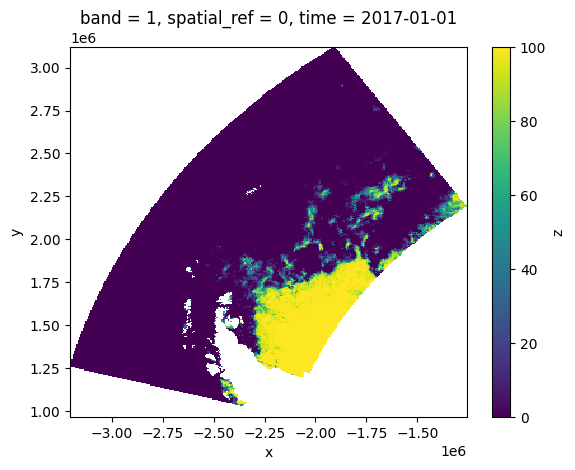

In [71]:
daily_sea_ice_cover.isel(time=0).plot()

In [72]:
daily_sea_ice_cover = daily_sea_ice_cover.where(daily_sea_ice_cover < 101)

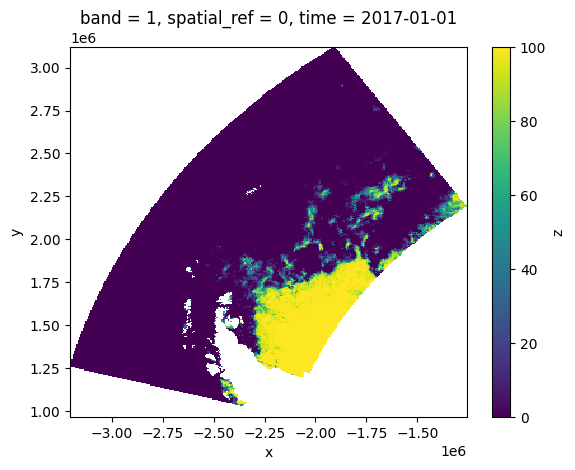

In [73]:
daily_sea_ice_cover.isel(time=0).plot()

In [84]:
from pyproj import Transformer

# Target lat/lon grid
lat = np.arange(-80, -50, 0.25)
lon = np.arange(-75, -20, 0.25)
lon2d, lat2d = np.meshgrid(lon, lat)

# Projection of the source data (NSIDC Antarctic polar stereographic)
crs = daily_sea_ice_cover.spatial_ref.attrs["crs_wkt"]  # or: "EPSG:3412"
transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
x_t, y_t = transformer.transform(lon2d, lat2d)

# Target points as DataArrays carrying the new lat/lon dims
x_t = xr.DataArray(x_t, dims=("latitude", "longitude"), coords={"latitude": lat, "longitude": lon})
y_t = xr.DataArray(y_t, dims=("latitude", "longitude"), coords={"latitude": lat, "longitude": lon})

five_day_sea_ice_cover = (
    daily_sea_ice_cover.resample(time="120h", origin=pd.Timestamp("2017-02-12"))
    .mean()  # resample first: cheaper than interpolating every day
    .sortby("y")  # y is descending; make it ascending for interp
    .interp(x=x_t, y=y_t)  # vectorized (pointwise) interpolation
)

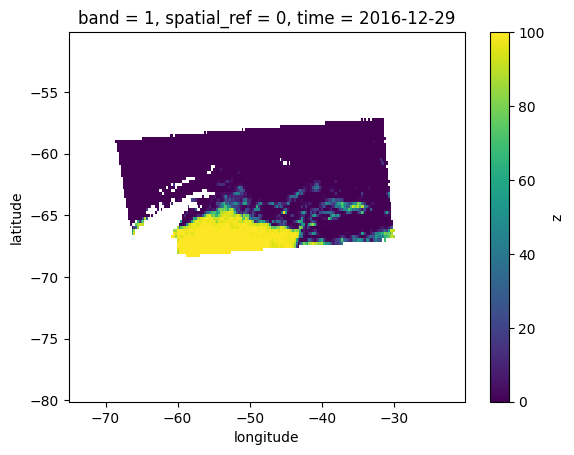

In [85]:
five_day_sea_ice_cover.isel(time=0).plot()

In [87]:
five_day_sea_ice_cover

<xarray.DataArray 'z' (time: 220, latitude: 120, longitude: 220)> Size: 46MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(220, 120, 220))
Coordinates:
  * time         (time) datetime64[us] 2kB 2016-12-29 2017-01-03 ... 2019-12-29
  * latitude     (latitude) float64 960B -80.0 -79.75 -79.5 ... -50.5 -50.25
  * longitude    (longitude) float64 2kB -75.0 -74.75 -74.5 ... -20.5 -20.25
    lat          (latitude, longitude) float64 211kB nan nan nan ... nan nan nan
    lon          (latitude, longitude) float64 211kB nan nan nan ... nan nan nan
    x            (latitude, longitude) float64 211kB -1.049e+06 ... -1.551e+06
    y            (latitude, longitude) float64 211kB 2.811e+05 ... 4.204e+06
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    TIFFTAG_IMAGEDESCRIPTION:  AMSR2 sea ice concentration using the ASI algo...
    TIFFTAG_SOFTWARE:          gdal and GMT
    TIFFTAG_ARTIST:            University of Bremen, Gunnar Spreen [gunnar.sp...
    AREA_OR_POINT:             Area
    actual_range:              [  0. 120.]
    long_name:                 z
    scale_factor:              1.0
    add_offset:                0.0

In [88]:
five_day_sea_ice_cover.to_zarr(INTERIM_DATA_DIR / "surface_stress_ice_cover.zarr", mode="w")

C:\Users\opinner\Desktop\Python\pinner2026_JPO_code\.venv\Lib\site-packages\zarr\api\asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


## Mooring specific sea ice concentration

In [89]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
list_of_moorings = pinner2026_jpo_code.IO.load_pickle(name="./mooring/list_of_moorings.pkl")
width_in_lon = 1.5
height_in_lat = 1

mooring_bins = {}
for name, mooring in zip(mooring_names, list_of_moorings):
    boxlats = np.array(
        [mooring.location.lat + height_in_lat / 2, mooring.location.lat - height_in_lat / 2]
    )
    boxlons = np.array(
        [mooring.location.lon + width_in_lon / 2, mooring.location.lon - width_in_lon / 2]
    )
    mooring_bins[name] = {"lat": boxlats, "lon": boxlons}
    print(mooring_bins[name])

FileNotFoundError: [Errno 2] No such file or directory: './mooring/list_of_moorings.pkl'

In [49]:
def setup_transect_view(fig):
    ax = fig.add_subplot(111, projection=ccrs.SouthPolarStereo(central_longitude=-50))
    # Limit the map to -60 degrees latitude and below.
    ax.set_extent([-54, -46, -64.5, -62.6], crs=ccrs.PlateCarree())
    # ax.set_extent([-55, -45, -65, -62], ccrs.PlateCarree())
    ax.gridlines(draw_labels=True)
    return ax

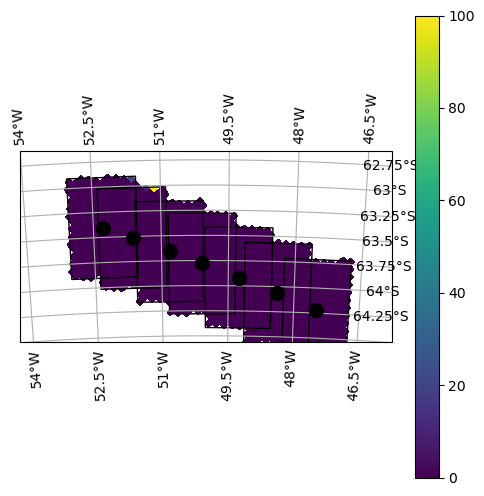

In [50]:
fig = plt.figure(figsize=(6, 6))
ax = setup_transect_view(fig)

ax.add_feature(cfeature.LAND, color="lightgrey", alpha=0.9, zorder=10)

list_of_time_series = []
for name, bounds in mooring_bins.items():
    ice_cover_at_mooring = daily_sea_ice_cover.where(
        (daily_sea_ice_cover.lat >= bounds["lat"][1])
        & (daily_sea_ice_cover.lat <= bounds["lat"][0])
        & (daily_sea_ice_cover.lon >= bounds["lon"][1])
        & (daily_sea_ice_cover.lon <= bounds["lon"][0]),
        drop=True,
    )

    list_of_time_series.append(ice_cover_at_mooring.mean(dim=["x", "y"]) / 100)
    """
    boxlat = surface_velocity_at_mooring.variables['lat'][:] # latitude grid points
    boxlon = surface_velocity_at_mooring.variables['lon'][:] # longitude grid points
    try:
        assert boxlat.size != 1
        assert boxlon.size != 1
    except AssertionError as e:
        print("Bins too small to contain more than 1 data point in all directions")
        print(f"size = {(boxlat.size,boxlon.size)}")
        raise e
    """
    # Compute monthly statistics averaged over space
    im = ax.pcolormesh(
        ice_cover_at_mooring.lon,
        ice_cover_at_mooring.lat,
        ice_cover_at_mooring.isel(time=0),
        vmin=0,
        vmax=100,
        transform=ccrs.PlateCarree(),
        # cmap = cmocean.cm.thermal,
        shading="nearest",
    )


for name, mooring in zip(mooring_names, list_of_moorings):
    ax.plot(mooring.location.lon, mooring.location.lat, "k.", ms=20, transform=ccrs.PlateCarree())

for mooring in list_of_moorings:
    patch = mpatches.Rectangle(
        xy=[mooring.location.lon - width_in_lon / 2, mooring.location.lat - height_in_lat / 2],
        width=width_in_lon,
        height=height_in_lat,
        facecolor="none",
        edgecolor="k",
        transform=ccrs.PlateCarree(),
    )

    assert np.all((patch.get_center() - (mooring.location.lon, mooring.location.lat)) < 0.01)
    ax.add_patch(patch)
plt.colorbar(im)

In [51]:
mooring_names = ["A", "B", "C", "D", "E", "F", "G"]
dict_of_time_series = {
    name: element.to_numpy() for name, element in zip(mooring_names, list_of_time_series)
}

In [71]:
sea_ice_concentrations = pd.DataFrame(
    data=dict_of_time_series, index=pd.to_datetime(ice_cover_at_mooring.time)
)
sea_ice_concentrations.sort_index(inplace=True)

<Axes: >

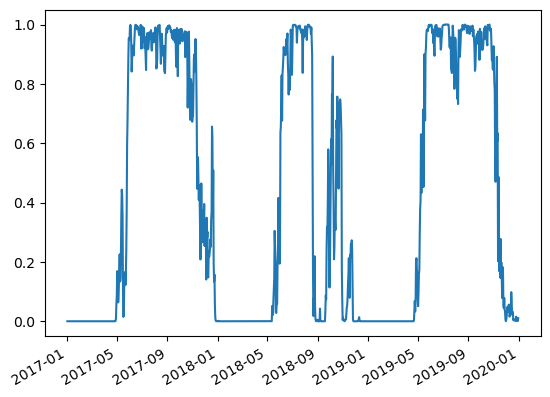

In [74]:
sea_ice_concentrations["C"].plot()

In [75]:
sea_ice_concentrations.to_csv("./daily_sea_ice_concentrations.csv")

# Sanity check

In [76]:
def clean_csv(df):
    if "Unnamed: 0" in df.columns:
        df.set_index(pd.to_datetime(df["Unnamed: 0"]), inplace=True)
        df.drop("Unnamed: 0", inplace=True, axis="columns")
    df = df.fillna(0)
    return df

In [56]:
monthly_sea_ice_concentrations = pd.read_csv("./monthly_sea_ice_concentrations.csv")
monthly_sea_ice_concentrations = clean_csv(monthly_sea_ice_concentrations)
monthly_sea_ice_concentrations = monthly_sea_ice_concentrations / 100

In [57]:
sea_ice_concentrations.index

DatetimeIndex(['2019-01-01', '2019-01-02', '2019-01-03', '2019-01-04',
               '2019-01-05', '2019-01-06', '2019-01-07', '2019-01-08',
               '2019-01-09', '2019-01-10',
               ...
               '2018-12-22', '2018-12-23', '2018-12-24', '2018-12-25',
               '2018-12-26', '2018-12-27', '2018-12-28', '2018-12-29',
               '2018-12-30', '2018-12-31'],
              dtype='datetime64[ns]', length=1094, freq=None)

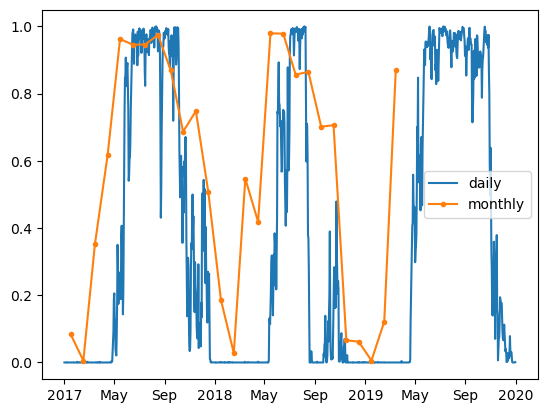

In [84]:
fig, ax = plt.subplots(1)
ax.plot(sea_ice_concentrations["A"].index, sea_ice_concentrations["A"], label="daily")
ax.plot(
    monthly_sea_ice_concentrations["A"].index + pd.Timedelta(days=15),
    monthly_sea_ice_concentrations["A"],
    marker=".",
    label="monthly",
)
ax.legend()

locator = mdates.AutoDateLocator()  # minticks=5, maxticks=7)
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

<Axes: >

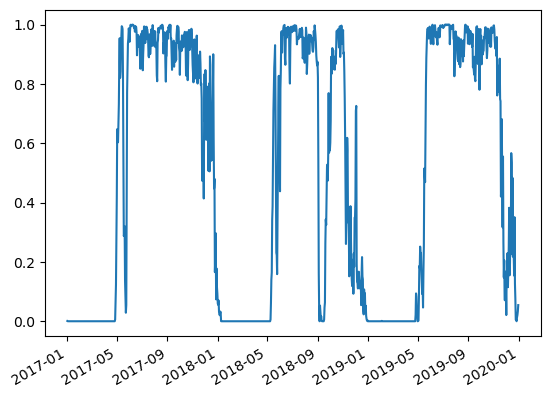

In [78]:
sea_ice_concentrations["G"].plot()